In [2]:
import pandas as pd
import numpy as np
import math

In [3]:
# Grid configuration

domain_w = 2.0  # domain width in meters   
domain_l = 1.0  # domain length in meters 
quartz_w = 0.01 # quartz width in meters
quartz_l = 0.01 # quartz length in meters

Nx_coarse = 500  # target columns in coarse grid
Ny_coarse = 250  # target rows in coarse grid
Nx_quartz = 10   # target columns of quartz cells
Ny_quartz = 10   # target rows of quartz cells


# make sure coarse and fine grid line up
while True:

    # fine grid cell sizes
    dx_fine = quartz_w / Nx_quartz
    dy_fine = quartz_l / Ny_quartz

    # fine grid columns and rows include 1-cell Aluminum walls
    Nx_fine = Nx_quartz + 2  
    Ny_fine = Ny_quartz + 2  

    # coarse grid cell sizes
    dx_coarse = domain_w / Nx_coarse
    dy_coarse = domain_l / Ny_coarse

    # refinement ratios coarse to fine
    m_x = dx_coarse / dx_fine   
    m_y = dy_coarse / dy_fine   

    # do the grid lines for the coarse and fine grid line up?
    if Nx_fine % m_x == 0:
        if Ny_fine % m_y == 0:
            break # the grids line up, so stop loop
            
    # if they don't align, increment quartz rows and columns to alter dx_fine and try again
    Nx_quartz += 1
    Ny_quartz += 1


# how many coarse columns and rows are swapped out by the fine grid
coarse_replaced_x = int(Nx_fine / m_x)
coarse_replaced_y = int(Ny_fine / m_y)


print(f"Quartz resolution: {Nx_quartz} x {Ny_quartz} fine cells")
print(f"Fine grid system (Aluminum walls included): {Nx_fine} x {Ny_fine} cells")
print(f"Coarse grid system: {Nx_coarse} x {Ny_coarse} cells")
print(f"Entire fine system replaces {coarse_replaced_x} x {coarse_replaced_y} coarse cells.")
print(f"Coarse cell size: {dx_coarse}m x {dy_coarse}m")
print(f"Fine cell size: {dx_fine}m x {dy_fine}m")

Quartz resolution: 10 x 10 fine cells
Fine grid system (Aluminum walls included): 12 x 12 cells
Coarse grid system: 500 x 250 cells
Entire fine system replaces 3 x 3 coarse cells.
Coarse cell size: 0.004m x 0.004m
Fine cell size: 0.001m x 0.001m


In [4]:
# Finding fine grid system coordinates in coarse grid system

quartz_center_x = 1.0  # center position from the left wall in meters
quartz_center_y = 0.5  # center position from the top wall in meters

# find the top-left coordinate of the Quartz block in physical space
quartz_top_left_x = quartz_center_x - (quartz_w / 2.0)
quartz_top_left_y = quartz_center_y - (quartz_l / 2.0)

# convert the physical top-left quartz location into coarse grid indices
quartz_start_i = int(np.floor(quartz_top_left_x / dx_coarse))
quartz_start_j = int(np.floor(quartz_top_left_y / dy_coarse))

# including the 1-cell Aluminum wall to find start of fine grid in coarse grid indices 
fine_start_i = int(np.floor(((quartz_top_left_x - dx_fine) / dx_coarse)))
fine_start_j = int(np.floor(((quartz_top_left_y - dy_fine) / dy_coarse)))

# including the 1-cell Aluminum wall to find end of fine grid in coarse grid indices 
fine_end_i = fine_start_i + coarse_replaced_x - 1
fine_end_j = fine_start_j + coarse_replaced_y - 1

print(f"Quartz physical top-left location: ({quartz_top_left_x}m, {quartz_top_left_y}m)")
print(f"Fine grid start: Column {fine_start_i}, Row {fine_start_j}")
print(f"Fine grid end: Column {fine_end_i}, Row {fine_end_j}")

Quartz physical top-left location: (0.995m, 0.495m)
Fine grid start: Column 248, Row 123
Fine grid end: Column 250, Row 125


In [5]:
# Defining master lookup table

rows = []

total_coarse = Nx_coarse * Ny_coarse
dirs = (("N", 0, -1), ("E", 1, 0), ("S", 0, 1), ("W", -1, 0))

for j in range(Ny_coarse):
    for i in range(Nx_coarse):
        
        # global index for temperature vector
        k = i + j * Nx_coarse
        
        # North, South, East, and West cell indices
        # if calculated cell index is outside of the grid system it is defined as None
        n_idx = i + (j - 1) * Nx_coarse if j > 0 else None
        s_idx = i + (j + 1) * Nx_coarse if j < Ny_coarse - 1 else None
        e_idx = (i + 1) + j * Nx_coarse if i < Nx_coarse - 1 else None
        w_idx = (i - 1) + j * Nx_coarse if i > 0 else None
        
        # boundary conditions 
        is_neumann_N   = (j == 0)                 # top edge
        is_dirichlet_S = (j == Ny_coarse - 1)     # bottom edge
        is_neumann_W   = (i == 0)                 # left edge
        is_neumann_E   = (i == Nx_coarse - 1)     # right edge 
        
        # check if this coarse cell is inside the fine grid region
        is_in_fine = (fine_start_i <= i <= fine_end_i) and (fine_start_j <= j <= fine_end_j)

        # check if at grid boundary and if so for what neighbour
        grid_bndry = None
        if not is_in_fine:
            for d, di, dj in dirs:
                if fine_start_i <= i + di <= fine_end_i and fine_start_j <= j + dj <= fine_end_j:
                    grid_bndry = d   # the neighbour in direction d is a fine cell
        
        rows.append({
            "temp_index": k, 
            "grid_resolution": "coarse", 
            "material": "Al",
            "spatial_i": i, 
            "spatial_j": j,
            # neighbour indices (global index for temperature vector)
            "neighbour_N": n_idx, "neighbour_E": e_idx, "neighbour_S": s_idx, "neighbour_W": w_idx,
            # boundary bools
            "bndry_dirichlet": is_dirichlet_S,
            "bndry_neumann": is_neumann_N or is_neumann_W or is_neumann_E,
            "bndry_material": False,
            "grid_bndry": grid_bndry,
            "in_fine": is_in_fine
        })


for j_q in range(Ny_fine):
    for i_q in range(Nx_fine):
        # global index for temperature vector (after all the coarse grid indices)
        k = total_coarse + (i_q + j_q * Nx_fine)
        
        # check to see if cell is the wall and hence Aluminum
        is_wall = (i_q == 0 or i_q == Nx_fine - 1 or j_q == 0 or j_q == Ny_fine - 1)
        material = "Al" if is_wall else "SiO2"
        
        # North, South, East, and West cell indices
        # if calculated cell index is outside of the grid system it is defined as None
        n_idx = total_coarse + i_q + (j_q - 1) * Nx_fine if j_q > 0 else None
        s_idx = total_coarse + i_q + (j_q + 1) * Nx_fine if j_q < Ny_fine - 1 else None
        e_idx = total_coarse + (i_q + 1) + j_q * Nx_fine if i_q < Nx_fine - 1 else None
        w_idx = total_coarse + (i_q - 1) + j_q * Nx_fine if i_q > 0 else None

        grid_bndry, mat_bndry = None, None
        for d, di, dj in dirs:
            ni, nj = i_q + di, j_q + dj
            if not (0 <= ni < Nx_fine and 0 <= nj < Ny_fine):
                grid_bndry = d   # the neighbour is outside the fine grid
            else:
                neighbour_is_wall = (ni == 0 or ni == Nx_fine - 1 or nj == 0 or nj == Ny_fine - 1)
                if neighbour_is_wall != is_wall:   # this cell and its neighbour are different materials
                    mat_bndry = d


        rows.append({
            "temp_index": k, 
            "grid_resolution": "fine", 
            "material": material,
            "spatial_i": i_q, 
            "spatial_j": j_q,
            # neighbour indices (global index for temperature vector)
            "neighbour_N": n_idx, "neighbour_E": e_idx, "neighbour_S": s_idx, "neighbour_W": w_idx,
            # boundary bools
            "bndry_dirichlet": False,
            "bndry_neumann": False,
            "grid_bndry_direction": grid_bndry,
            "material_bndry_direction": mat_bndry 
        })


lookup_df = pd.DataFrame(rows).set_index("temp_index")

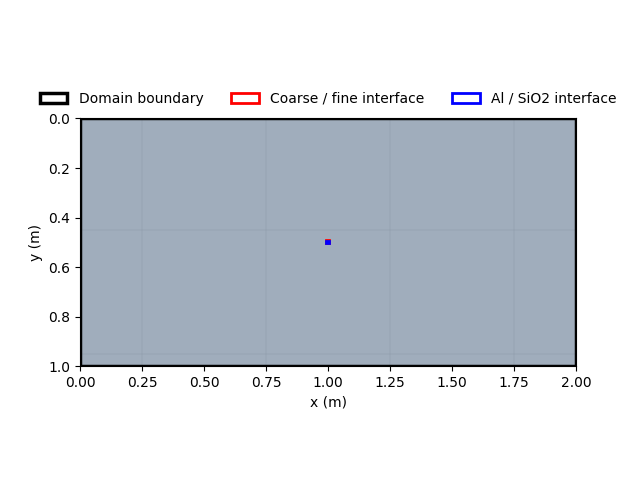

In [6]:
# you need to pip install -U matplotlib ipympl ipywidgets
# zoom in by pressing 'Z', zoom out by pressing 'X'
# produced by AI to make sure grid system is correct

%matplotlib widget
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# draw one filled rectangle with its top-left corner at (x, y); edge/lw give it an optional outline
def DrawRectangle(ax, x, y, dx, dy, colour, edge="none", lw=0, **kw):
    ax.add_patch(Rectangle((x, y), dx, dy, facecolor=colour, edgecolor=edge, linewidth=lw, **kw))

AL, SIO2 = "#c9d6e3", "#f6d6a8"
fx0, fy0 = fine_start_i * dx_coarse, fine_start_j * dy_coarse   # top-left of fine block (m)
fine_w, fine_h = coarse_replaced_x * dx_coarse, coarse_replaced_y * dy_coarse

fig, ax = plt.subplots()

# coarse grid: one Al rectangle for the whole domain, then thin lines to separate the cells
DrawRectangle(ax, 0, 0, domain_w, domain_l, AL)
ax.vlines(np.arange(Nx_coarse + 1) * dx_coarse, 0, domain_l, colors="#8896a5", linewidths=0.3)
ax.hlines(np.arange(Ny_coarse + 1) * dy_coarse, 0, domain_w, colors="#8896a5", linewidths=0.3)

# fine grid: one outlined rectangle per fine cell, coloured by the material stored in lookup_df
for r in lookup_df[lookup_df["grid_resolution"] == "fine"].itertuples():
    DrawRectangle(ax, fx0 + r.spatial_i * dx_fine, fy0 + r.spatial_j * dy_fine, dx_fine, dy_fine,
                  SIO2 if r.material == "SiO2" else AL, edge="#777777", lw=0.4, zorder=2)

# the three borders (outline only, no fill)
for (x, y, w, h), c, lw, name in [
    ((0, 0, domain_w, domain_l), "black", 2.5, "Domain boundary"),
    ((fx0, fy0, fine_w, fine_h), "red", 2, "Coarse / fine interface"),
    ((fx0 + dx_fine, fy0 + dy_fine, Nx_quartz * dx_fine, Ny_quartz * dy_fine), "blue", 2, "Al / SiO2 interface")]:
    ax.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor=c, linewidth=lw, zorder=4, label=name))
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False)

# "k" global index for temperature vector
texts = []
def label_grid(x0, y0, dx, dy, ni, nj, row_width, index_offset=0, skip=lambda i, j: False):
    xa, xb = sorted(ax.get_xlim())
    ya, yb = sorted(ax.get_ylim())
    box = ax.get_window_extent()
    w_pt = dx * box.width / (xb - xa) * 72 / fig.dpi
    h_pt = dy * box.height / (yb - ya) * 72 / fig.dpi
    fs = min(w_pt / 5, h_pt / 1.5)
    if fs < 4:
        return

    for j in range(max(int((ya - y0) // dy), 0), min(int((yb - y0) // dy), nj - 1) + 1):
        for i in range(max(int((xa - x0) // dx), 0), min(int((xb - x0) // dx), ni - 1) + 1):
            if not skip(i, j):
                temp_index = index_offset + i + j * row_width
                texts.append(ax.text(
                    x0 + (i + .5) * dx, y0 + (j + .5) * dy, str(temp_index),
                    ha="center", va="center", fontsize=fs, zorder=5, clip_on=True
                ))

# redraw the labels whenever the view changes
def update_labels(event=None):
    for t in texts:
        t.remove()
    texts.clear()
    ax.apply_aspect()                                     # make the plot-area size current before measuring
    in_fine = lambda i, j: fine_start_i <= i <= fine_end_i and fine_start_j <= j <= fine_end_j
    label_grid(0, 0, dx_coarse, dy_coarse, Nx_coarse, Ny_coarse,
               row_width=Nx_coarse, skip=in_fine)
    label_grid(fx0, fy0, dx_fine, dy_fine, Nx_fine, Ny_fine,
               row_width=Nx_fine, index_offset=total_coarse)                 


ax.set_aspect("equal")
ax.set_xlim(0, domain_w)
ax.set_ylim(domain_l, 0)                                  # j = 0 is the top row
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")

# optional: start zoomed in on the fine block instead of the whole domain
# ax.set_xlim(fx0 - 0.03, fx0 + fine_w + 0.03); ax.set_ylim(fy0 + fine_h + 0.02, fy0 - 0.02)
def on_key(event):
    if event.key not in ("z", "x"):
        return
    s = 0.6 if event.key == "z" else 1.25                # z shrinks the view (zoom in), x enlarges it (zoom out)
    xa, xb = ax.get_xlim(); ya, yb = ax.get_ylim()
    cx = event.xdata if event.xdata is not None else (xa + xb) / 2   # xdata is None when the cursor is off the plot
    cy = event.ydata if event.ydata is not None else (ya + yb) / 2
    ax.set_xlim(cx - (cx - xa) * s, cx + (xb - cx) * s)
    ax.set_ylim(cy - (cy - ya) * s, cy + (yb - cy) * s)

fig.canvas.mpl_connect("key_press_event", on_key)
ax.callbacks.connect("xlim_changed", update_labels)
ax.callbacks.connect("ylim_changed", update_labels)

update_labels()
plt.show()

In [ ]:
# Defining physical variables of materials and overall system

# Aluminum properties
kappa_0_Al = 0.8 # kappa_Al (thermal conductivity) = kappa_0_Al * u^3, [units: W/m*K^4]
beta_Al = 0.11119 # c_Al (specific heat capacity) = beta_Al * u^3, [units: J/kg*K^4]
rho_Al = 2700 # mass density, [units: kg/m^3]

# Quartz (SiO2) properties (PLACEHOLDERS -> LOOK UP IN POBELL)
kappa_0_Q = 1.38 # kappa_Q (thermal conductivity) = kappa_0_Q * u^3, [units: W/m*K^4]
beta_Q = 0.765 # c_Q (specific heat capacity) = beta_Q * u^3, [units: J/kg*K^4]
rho_Q = 2650 # mass density, [units: kg/m^3]

q_dot_max = 10.0 # volumetric heat generation at top left corner [units: W/m^3 = J/s*m^3]
q_dot_min = 0.0 # volumetric heat generation everywhere else [units: W/m^3 = J/s*m^3]
q_dot = np.full(len(lookup_df), q_dot_min) # volumetric heat generation at each element
q_dot[0] = q_dot_max # there is a heater in the top left corner (temp_index = 0)

u_fixed = 1.e-5 # fixed temperature for Dirichlet boundary condition (bottom wall), = 10mK [units: K]

# PLACEHOLDER -> CHANGE LATER
C = 1.0 # R_K (Kapitza resistance between Aluminum and Quartz) = C/A*T^3, [units: m^2*K^4/W] 

In [ ]:
# PLACEHOLDER -> CHANGE LATER
dt = 0.01 # time step [units: s]

In [ ]:
# Defining constants that are coefficients in the systems of equations

# constants for coarse grid Aluminum cells
a_P_Al = ((rho_Al * beta_Al * dx_coarse * dy_coarse)/4)*(1/m_x)*(1/m_y)
a_x_Al = ((kappa_0_Al * dt * dy_coarse)/(4 * dx_coarse))*(1/m_x)*(1/m_y)
a_y_Al = ((kappa_0_Al * dt * dx_coarse)/(4 * dy_coarse))*(1/m_x)*(1/m_y)
b_Al = (q_dot * dx_coarse * dy_coarse * dt)*(1/m_x)*(1/m_y)
# multiply by 1/m_x and 1/m_y to account for the fact that the coarse grid cell is replaced by m_x * m_y fine grid cells

a_x_Al_Q = 
